# 03 · Model evaluation
The full experiment is run by `python -m src.run_pipeline`, which writes `outputs/metrics.json`. This notebook reads those results, and re-fits Logistic Regression inline and recomputes the metrics from the saved predictions, to show the reported numbers are reproducible.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
from IPython.display import Image, display
from src import config as C, load_data as L, preprocessing as P, features as F
from src import train as T, evaluate as E
R = json.loads((C.OUTPUT_DIR / 'metrics.json').read_text())

## Reproduce the Logistic Regression result

In [2]:
ratings, movies = L.load_ratings(), L.load_movies()
split_df, _ = P.chronological_split(P.add_target(ratings))
X, y, meta, _ = F.build_features(split_df, movies)
tr, va, te = (meta.split == s for s in ['train', 'val', 'test'])
lr = T.make_logreg(R['tuning']['Logistic Regression']['chosen_C']).fit(X[tr], y[tr])
thr, _ = T.choose_threshold(y[va], lr.predict_proba(X[va])[:, 1])
m = E.classification_metrics(y[te], lr.predict_proba(X[te])[:, 1], thr)
print('re-computed:', {k: m[k] for k in ['f1','pr_auc','precision','recall']})
print('reported   :', {k: R['test']['Logistic Regression'][k] for k in ['f1','pr_auc','precision','recall']})

re-computed: {'f1': 0.7322, 'pr_auc': 0.7462, 'precision': 0.6226, 'recall': 0.8888}
reported   : {'f1': 0.7322, 'pr_auc': 0.7462, 'precision': 0.6226, 'recall': 0.8888}


## Verify the saved predictions and the split
`outputs/test_predictions.csv` holds no MovieLens IDs or ratings (the licence forbids redistribution). Row *i* is the *i*-th test rating in split order, so it can be joined back to the data you downloaded. This cell checks the split fingerprint, that the saved scores match the model re-fitted above, and recomputes the reported test metrics from the saved file.

In [3]:
_, info = P.chronological_split(P.add_target(ratings))
print('split fingerprint matches:', info['assignment_sha256'] == R['split']['assignment_sha256'])
# round_trip parsing: scores tied with a threshold must be read back bit-for-bit
saved = pd.read_csv(C.OUTPUT_DIR / 'test_predictions.csv', float_precision='round_trip')
y_test = y[te].reset_index(drop=True)
assert len(saved) == len(y_test)
print('saved LR scores match re-fitted model:',
      np.allclose(saved['fixed|Logistic Regression'], lr.predict_proba(X[te])[:, 1], atol=1e-5))
rows = []
for proto, key in [('fixed', 'test'), ('sequential', None)]:
    block = R['test'] if key else R['sequential']['test']
    thr = R['thresholds'] if key else R['sequential']['thresholds']   # full precision
    for m in block:
        got = E.classification_metrics(y_test, saved[f'{proto}|{m}'].to_numpy(), thr[m])
        rows.append({'protocol': proto, 'model': m, 'pr_auc (recomputed)': got['pr_auc'],
                     'pr_auc (reported)': block[m]['pr_auc'], 'f1 (recomputed)': got['f1'], 'f1 (reported)': block[m]['f1']})
check = pd.DataFrame(rows)
print('all recomputed values equal the reported ones:',
      (check['pr_auc (recomputed)'] == check['pr_auc (reported)']).all() and (check['f1 (recomputed)'] == check['f1 (reported)']).all())
check


split fingerprint matches: True
saved LR scores match re-fitted model: True


all recomputed values equal the reported ones: True


,protocol,model,pr_auc (recomputed),pr_auc (reported),f1 (recomputed),f1 (reported)
0,fixed,Majority baseline,0.5629,0.5629,0.7203,0.7203
1,fixed,Popularity baseline,0.7425,0.7425,0.7370,0.7370
2,fixed,Logistic Regression,0.7462,0.7462,0.7322,0.7322
3,fixed,Random Forest,0.7403,0.7403,0.7306,0.7306
4,fixed,LR (movie features only),0.7462,0.7462,0.7352,0.7352
5,sequential,Majority baseline,0.5629,0.5629,0.7203,0.7203
6,sequential,Popularity baseline,0.7449,0.7449,0.7349,0.7349
7,sequential,Logistic Regression,0.7755,0.7755,0.7575,0.7575
8,sequential,Random Forest,0.7772,0.7772,0.7554,0.7554
9,sequential,LR (movie features only),0.7481,0.7481,0.7357,0.7357


## Tuning log (validation PR-AUC)

In [4]:
{k: v['log'] for k, v in R['tuning'].items()}

{'Logistic Regression': [{'param': 0.001, 'val_pr_auc': 0.726},
  {'param': 0.01, 'val_pr_auc': 0.7254},
  {'param': 0.1, 'val_pr_auc': 0.7252},
  {'param': 1.0, 'val_pr_auc': 0.7252},
  {'param': 10.0, 'val_pr_auc': 0.7252}],
 'Random Forest': [{'param': 5, 'val_pr_auc': 0.7175},
  {'param': 20, 'val_pr_auc': 0.7244},
  {'param': 50, 'val_pr_auc': 0.7253},
  {'param': 100, 'val_pr_auc': 0.7256}],
 'LR (movie features only)': [{'param': 0.001, 'val_pr_auc': 0.7225},
  {'param': 0.01, 'val_pr_auc': 0.7221},
  {'param': 0.1, 'val_pr_auc': 0.7219},
  {'param': 1.0, 'val_pr_auc': 0.7219},
  {'param': 10.0, 'val_pr_auc': 0.7219}]}

## Primary results: fixed snapshot, test set

In [5]:
def table(d):
    t = pd.DataFrame(d).T
    return t[['threshold','accuracy','precision','recall','f1','pr_auc','roc_auc']]
table(R['test'])

,threshold,accuracy,precision,recall,f1,pr_auc,roc_auc
Majority baseline,0.5,0.5629,0.5629,1.0,0.7203,0.5629,0.5
Popularity baseline,0.3957,0.6337,0.6185,0.9117,0.737,0.7425,0.7049
Logistic Regression,0.39,0.6341,0.6226,0.8888,0.7322,0.7462,0.7043
Random Forest,0.3966,0.6385,0.6293,0.8708,0.7306,0.7403,0.7005
LR (movie features only),0.3892,0.6448,0.6334,0.876,0.7352,0.7462,0.7086


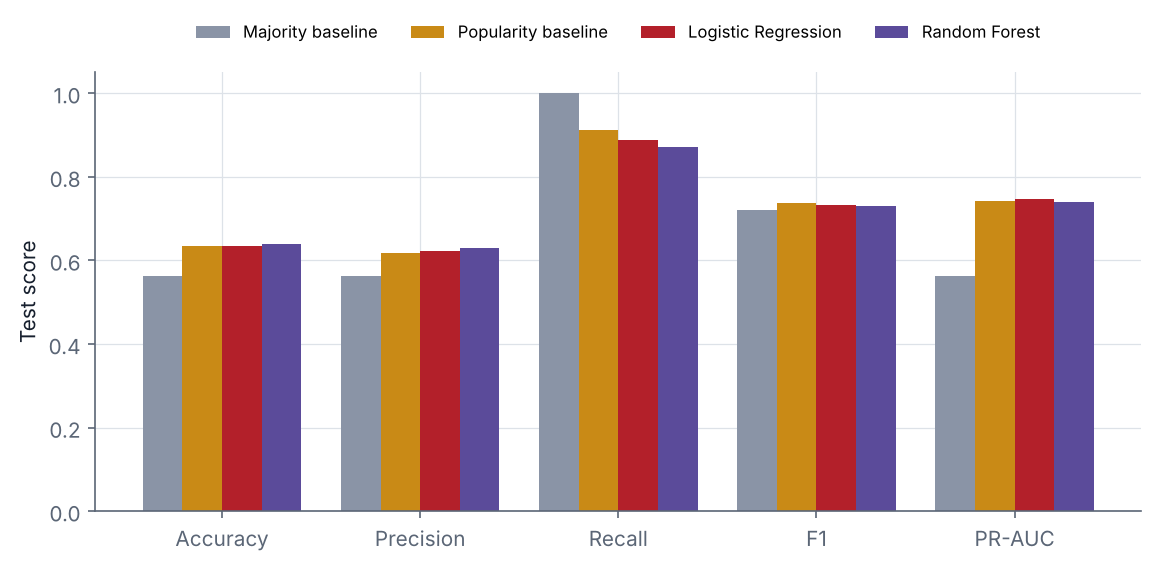

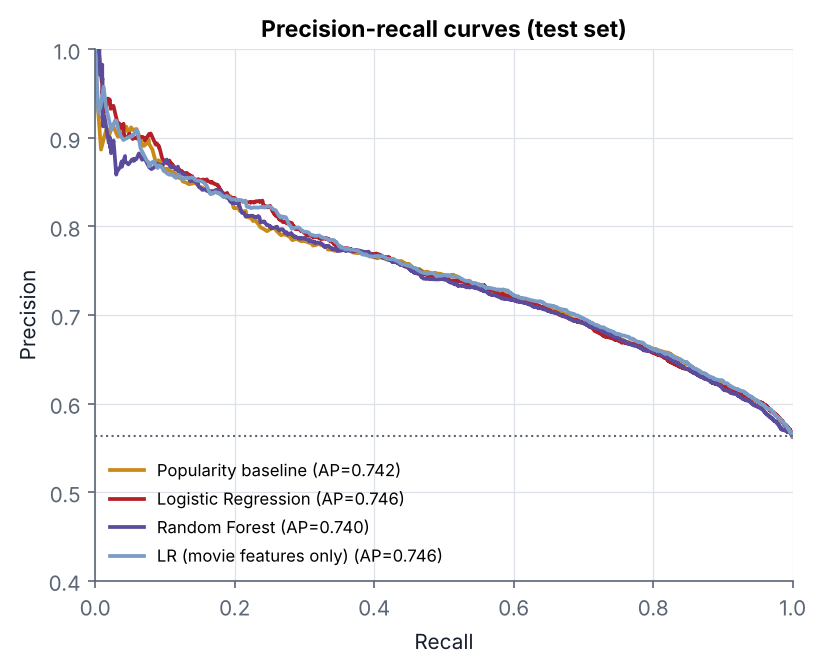

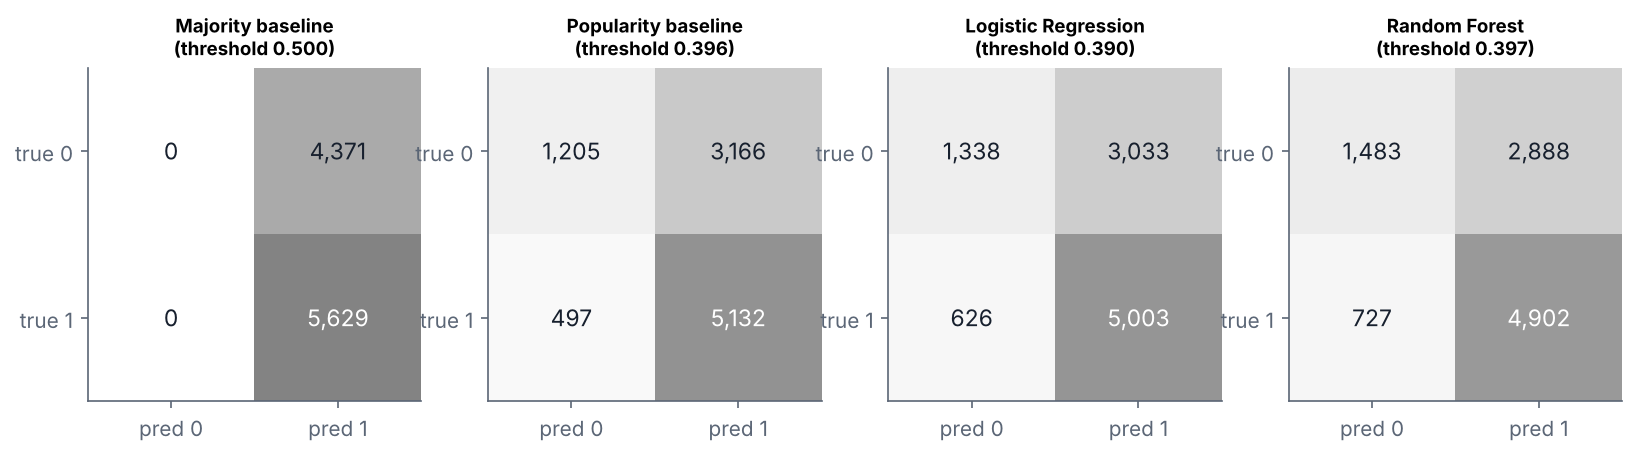

In [6]:
display(Image(str(C.FIG_DIR / 'results_metric_comparison.png')))
display(Image(str(C.FIG_DIR / 'results_pr_curves.png')))
display(Image(str(C.FIG_DIR / 'results_confusion_matrices.png')))

In [7]:
pd.DataFrame(R['bootstrap_pr_auc_diff']['fixed_snapshot']).T

,diff,ci95,share_boot_positive,n_boot,clusters
LR - Popularity,0.0038,"[-0.0118, 0.0172]",0.736,1000,166
LR - LR(movie only),0.0001,"[-0.015, 0.0133]",0.532,1000,166
RF - LR,-0.0059,"[-0.0118, 0.0003]",0.03,1000,166


## By amount of user history

In [8]:
pd.DataFrame(R['test_by_user_history']).set_index('group')

,n,positive_rate,Popularity baseline|f1,Popularity baseline|accuracy,Popularity baseline|pr_auc,Logistic Regression|f1,Logistic Regression|accuracy,Logistic Regression|pr_auc,Random Forest|f1,Random Forest|accuracy,Random Forest|pr_auc
group,,,,,,,,,,,
0 (cold start),8582,0.5590,0.7339,0.6284,0.7380,0.7317,0.6290,0.7414,0.7314,0.6363,0.7349
1-49,162,0.5185,0.6887,0.5926,0.6891,0.6564,0.5864,0.7112,0.6564,0.5864,0.7040
50-199,783,0.5351,0.7507,0.6794,0.7938,0.7447,0.6628,0.7949,0.7332,0.6450,0.7833
200+,473,0.6956,0.7834,0.6681,0.8029,0.7465,0.6956,0.9012,0.7344,0.6850,0.9026


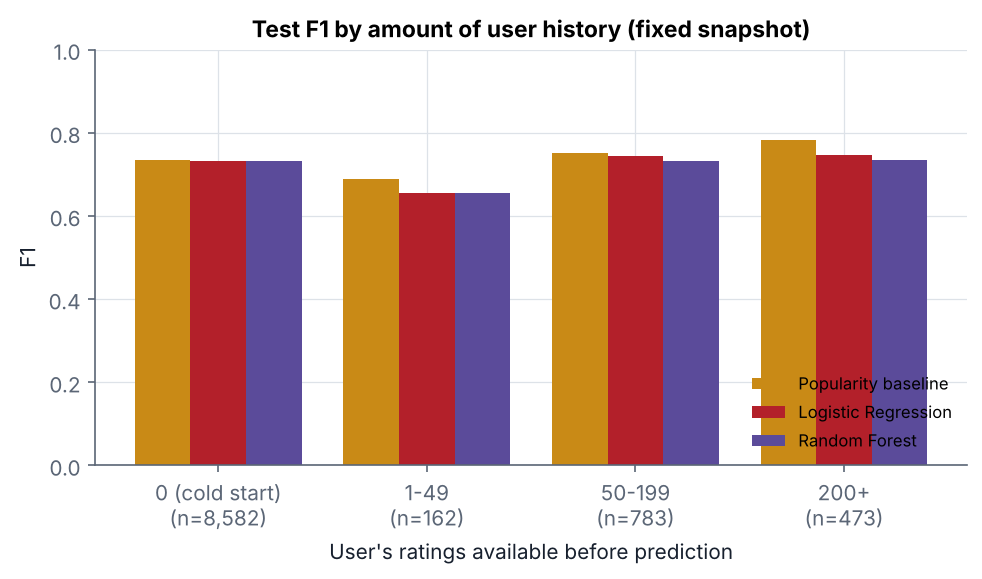

In [9]:
display(Image(str(C.FIG_DIR / 'results_f1_by_user_history.png')))

## Secondary results: sequential protocol

In [10]:
table(R['sequential']['test'])

,threshold,accuracy,precision,recall,f1,pr_auc,roc_auc
Majority baseline,0.5,0.5629,0.5629,1.0,0.7203,0.5629,0.5
Popularity baseline,0.4241,0.6456,0.6347,0.8728,0.7349,0.7449,0.7071
Logistic Regression,0.3737,0.6805,0.6613,0.8865,0.7575,0.7755,0.7477
Random Forest,0.4026,0.6826,0.667,0.8708,0.7554,0.7772,0.7482
LR (movie features only),0.3902,0.6468,0.6355,0.8735,0.7357,0.7481,0.7101


In [11]:
pd.DataFrame(R['bootstrap_pr_auc_diff']['sequential']).T

,diff,ci95,share_boot_positive,n_boot,clusters
LR - Popularity,0.0307,"[0.01, 0.0502]",0.999,1000,166
LR - LR(movie only),0.0275,"[0.0075, 0.0461]",0.997,1000,166
RF - LR,0.0017,"[-0.0017, 0.0054]",0.837,1000,166


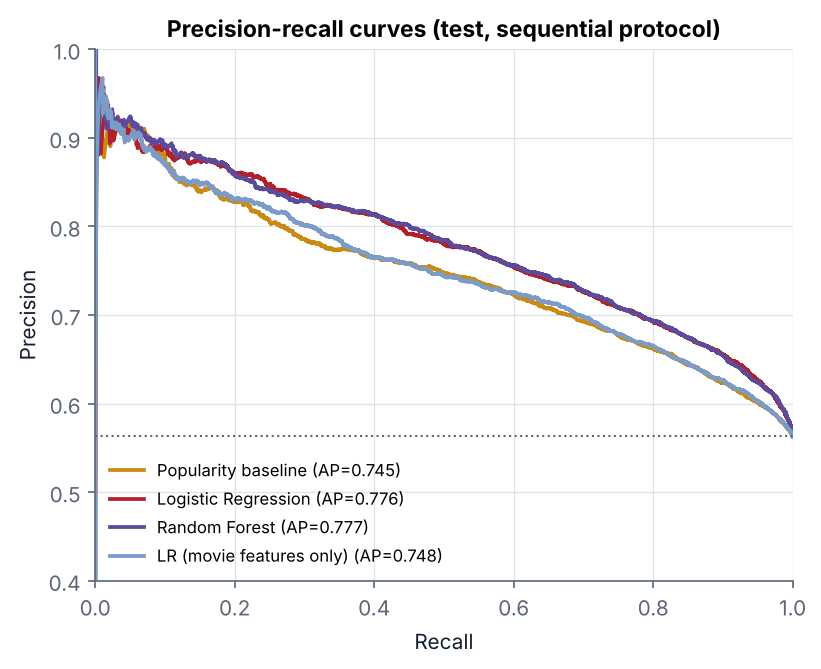

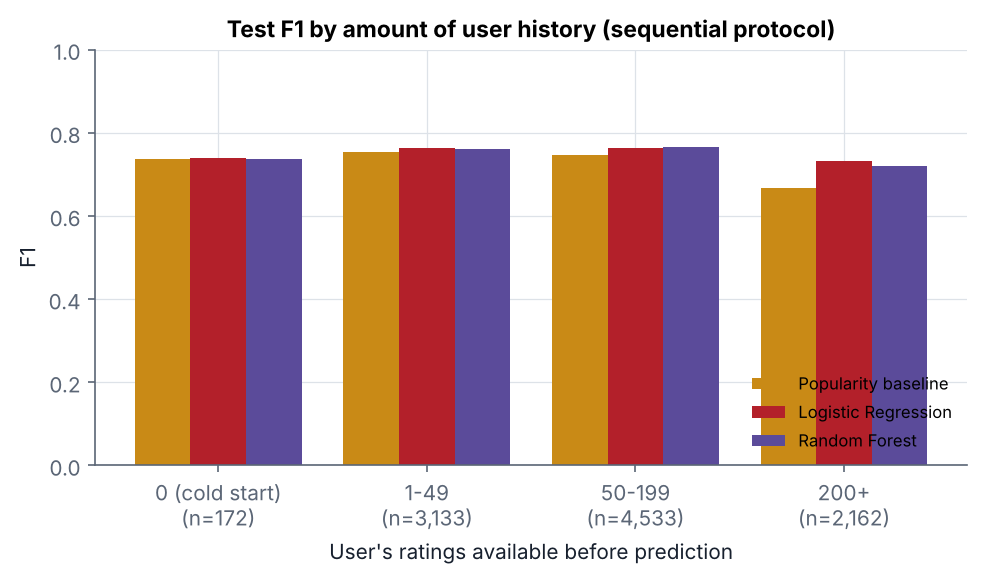

In [12]:
display(Image(str(C.FIG_DIR / 'results_pr_curves_sequential.png')))
display(Image(str(C.FIG_DIR / 'results_f1_by_user_history_sequential.png')))

## Ranking within each user's rated movies

In [13]:
pd.DataFrame({'fixed_snapshot': R['ranking_test']['models'], 'sequential': R['sequential']['ranking_test']['models']}).T

,Popularity baseline,Logistic Regression,Random Forest
fixed_snapshot,"{'p@5': 0.7929, 'p@10': 0.7575, 'mean_user_ap'...","{'p@5': 0.7929, 'p@10': 0.7513, 'mean_user_ap'...","{'p@5': 0.7717, 'p@10': 0.7425, 'mean_user_ap'..."
sequential,"{'p@5': 0.7876, 'p@10': 0.7566, 'mean_user_ap'...","{'p@5': 0.7611, 'p@10': 0.7416, 'mean_user_ap'...","{'p@5': 0.7469, 'p@10': 0.7416, 'mean_user_ap'..."


## Interpretation, errors, leakage demo, sensitivity

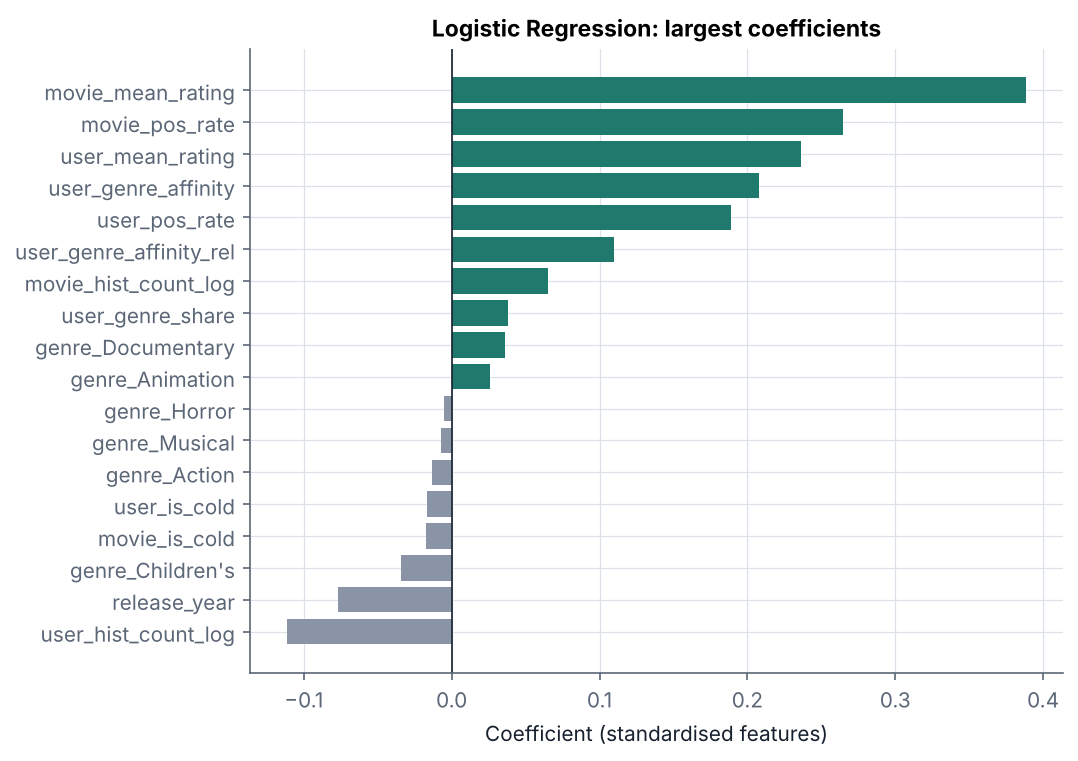

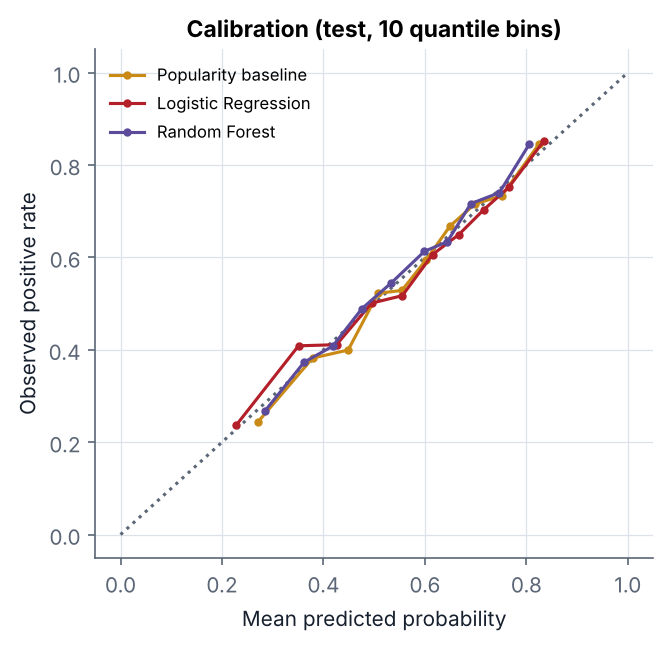

In [14]:
display(Image(str(C.FIG_DIR / 'results_lr_coefficients.png')))
display(Image(str(C.FIG_DIR / 'results_calibration.png')))

In [15]:
pd.DataFrame(R['error_examples']['false_positives'])

,user_id,title,rating,p,user_hist_count,movie_hist_count,movie_pos_rate,user_pos_rate,user_genre_affinity
0,58,It's a Wonderful Life (1946),2,0.886,126.0,179.0,0.749,0.754,0.784
1,125,"Manchurian Candidate, The (1962)",3,0.879,80.0,93.0,0.850,0.644,0.695
2,125,Dr. Strangelove or: How I Learned to Stop Worr...,3,0.876,80.0,154.0,0.784,0.644,0.763
3,94,Six Degrees of Separation (1993),3,0.868,82.0,56.0,0.690,0.859,0.938
4,669,Casablanca (1942),3,0.890,0.0,186.0,0.880,0.551,0.551
5,911,Casablanca (1942),3,0.890,0.0,186.0,0.880,0.551,0.551
6,807,"Close Shave, A (1995)",3,0.864,0.0,94.0,0.870,0.551,0.551


In [16]:
pd.DataFrame(R['error_examples']['false_negatives'])

,user_id,title,rating,p,user_hist_count,movie_hist_count,movie_pos_rate,user_pos_rate,user_genre_affinity
0,416,Tales from the Hood (1995),4,0.072,279.0,23.0,0.197,0.450,0.405
1,186,"Beautician and the Beast, The (1997)",4,0.101,67.0,73.0,0.199,0.497,0.439
2,708,Free Willy 3: The Rescue (1997),4,0.104,44.0,24.0,0.221,0.485,0.613
3,655,Love and Death on Long Island (1997),4,0.116,601.0,0.0,0.551,0.175,0.074
4,381,"Island of Dr. Moreau, The (1996)",4,0.144,0.0,48.0,0.147,0.551,0.551
5,489,Mortal Kombat: Annihilation (1997),5,0.154,0.0,34.0,0.239,0.551,0.551
6,807,Speed 2: Cruise Control (1997),4,0.156,0.0,31.0,0.183,0.551,0.551


In [17]:
print(R['error_examples']['fp_summary']); print(R['error_examples']['fn_summary'])
pd.DataFrame(R['test_errors_by_genre']).head(8)

{'n': 3033, 'share_cold_user': 0.8998, 'mean_rating': 2.583, 'share_rated_3': 0.6739}
{'n': 626, 'share_cold_user': 0.7268, 'mean_rating': 4.345, 'share_rated_4': 0.655}


,genre,n,error_rate,fp_rate_of_rows,fn_rate_of_rows
0,Action,2469,0.3937,0.2973,0.0964
1,Romance,1983,0.3923,0.3449,0.0474
2,Horror,515,0.3903,0.2990,0.0913
3,Adventure,1278,0.3826,0.2942,0.0884
4,Musical,502,0.3745,0.2968,0.0777
5,Comedy,2934,0.3722,0.3091,0.0631
6,Thriller,2224,0.3710,0.2887,0.0823
7,Crime,822,0.3674,0.3309,0.0365


In [18]:
R['leakage_demo']

{'description': "LR trained on training-row features that include each row's own rating (naive snapshot) vs. the correct strictly-earlier features. Validation only.",
 'leaky': {'train_pr_auc': 0.8549, 'val_pr_auc': 0.6991},
 'correct': {'train_pr_auc': 0.7738, 'val_pr_auc': 0.726}}

In [19]:
table(R['sensitivity_exclude_3star']['test'])

,threshold,accuracy,precision,recall,f1,pr_auc,roc_auc
Majority baseline,0.5,0.7688,0.7688,1.0,0.8693,0.7688,0.5
Popularity baseline,0.5081,0.7939,0.8065,0.9629,0.8778,0.9108,0.7755
Logistic Regression,0.4113,0.7955,0.804,0.9707,0.8795,0.9138,0.7784
